# EXPERIMent NO. 10 B (Data Visualization using matplotlib)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

%matplotlib inline

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

In [5]:
data = pd.read_csv("delhi-weather-aqi-2025.csv")

print("Dataset loaded successfully!")
print("Shape:", data.shape)

data.head()

print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

print("\nColumn names:")
print(data.columns.tolist())

Dataset loaded successfully!
Shape: (52560, 16)
Number of rows: 52560
Number of columns: 16

Column names:
['date_ist', 'time_ist', 'location', 'lat', 'lon', 'temp_c', 'humidity', 'pressure_mb', 'windspeed_kph', 'condition_text', 'description', 'aqi_index', 'pm2_5', 'pm10', 'co', 'no2']


In [6]:
print("Missing values:")
print(data.isnull().sum())

Missing values:
date_ist          0
time_ist          0
location          0
lat               0
lon               0
temp_c            0
humidity          0
pressure_mb       0
windspeed_kph     0
condition_text    0
description       0
aqi_index         0
pm2_5             0
pm10              0
co                0
no2               0
dtype: int64


In [7]:
data["datetime"] = pd.to_datetime(
    data["date_ist"] + " " + data["time_ist"],
    dayfirst=True,
    errors="coerce"
)

print(data[["date_ist", "time_ist", "datetime"]].head())

     date_ist time_ist            datetime
0  01/01/2025     0:00 2025-01-01 00:00:00
1  01/01/2025     1:00 2025-01-01 01:00:00
2  01/01/2025     2:00 2025-01-01 02:00:00
3  01/01/2025     3:00 2025-01-01 03:00:00
4  01/01/2025     4:00 2025-01-01 04:00:00


In [8]:
data = data.sort_values("datetime")
data.head()
print("Number of locations:", data["location"].nunique())

print("\nLocations:")
print(data["location"].unique())

Number of locations: 6

Locations:
['Anand Vihar' 'Okhla Phase III' 'Dwarka' 'IGI Airport' 'Connaught Place'
 'Rohini']


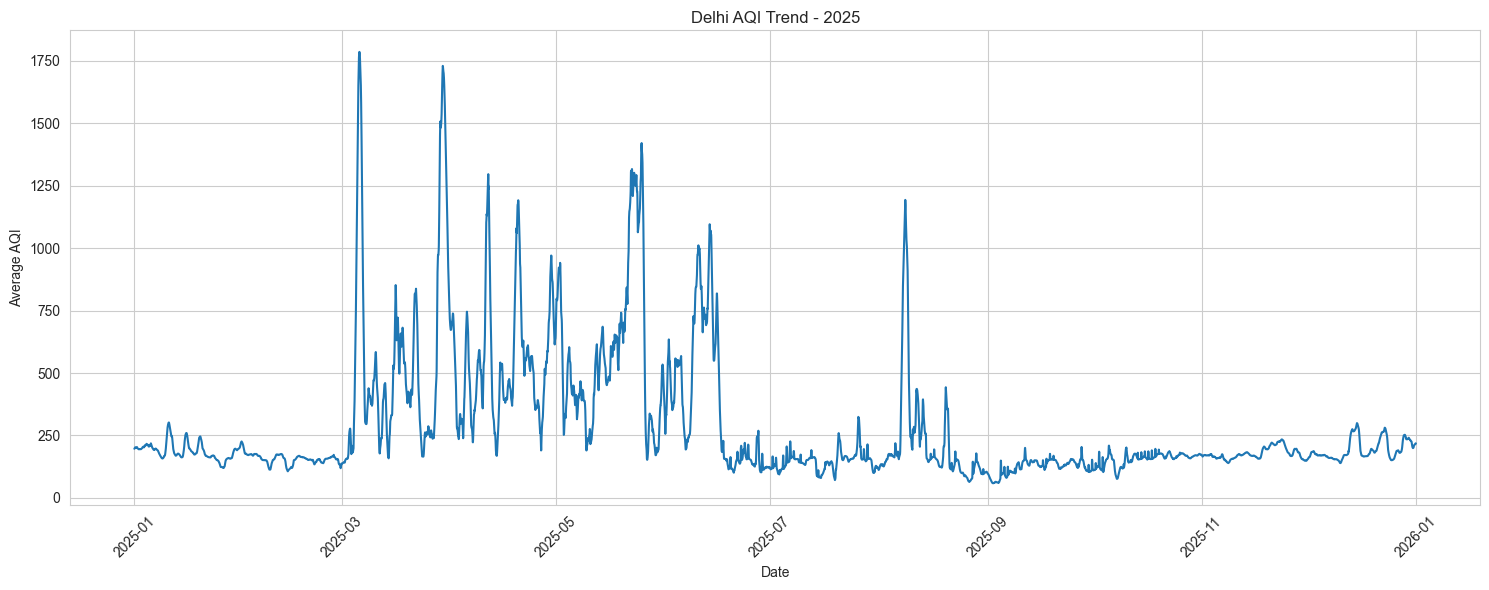

In [9]:
hourly_aqi = data.groupby("datetime")["aqi_index"].mean()

plt.figure(figsize=(15, 6))

plt.plot(
    hourly_aqi.index,
    hourly_aqi.values
)

plt.title("Delhi AQI Trend - 2025")
plt.xlabel("Date")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [11]:
daily_pollutants = data.groupby(
    data["datetime"].dt.date
)[["pm2_5", "pm10", "co", "no2"]].mean()

daily_pollutants.head()

,pm2_5,pm10,co,no2
datetime,,,,
2025-01-01,144.972917,147.768750,1386.694444,38.368750
2025-01-02,144.433333,148.554167,1554.166667,37.108333
2025-01-03,161.204167,169.950000,2091.631944,61.100000
2025-01-04,157.579167,165.727083,2519.375000,71.227083
2025-01-05,154.581250,160.452083,1618.611111,39.468750


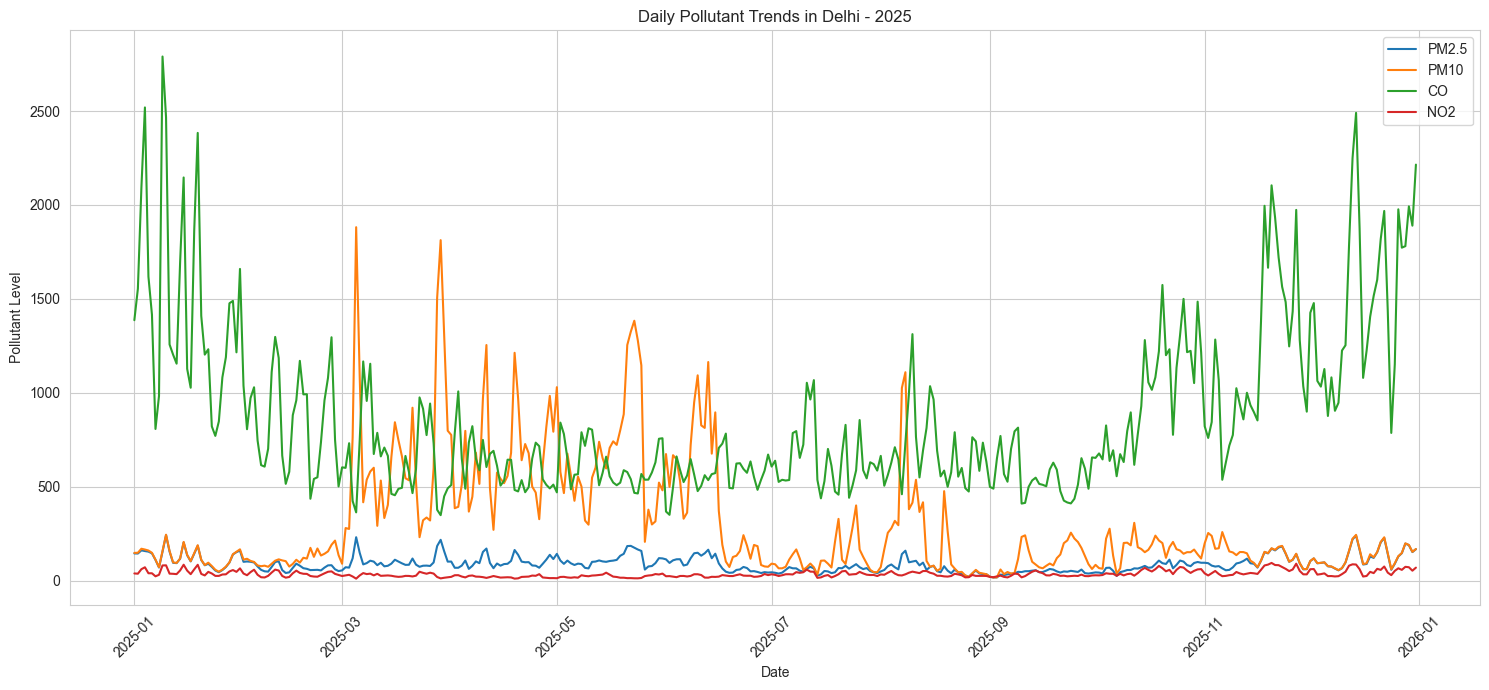

In [14]:
plt.figure(figsize=(15, 7))

plt.plot(
    daily_pollutants.index,
    daily_pollutants["pm2_5"],
    label="PM2.5"
)

plt.plot(
    daily_pollutants.index,
    daily_pollutants["pm10"],
    label="PM10"
)

plt.plot(
    daily_pollutants.index,
    daily_pollutants["co"],
    label="CO"
)

plt.plot(
    daily_pollutants.index,
    daily_pollutants["no2"],
    label="NO2"
)

plt.title("Daily Pollutant Trends in Delhi - 2025")
plt.xlabel("Date")
plt.ylabel("Pollutant Level")

plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

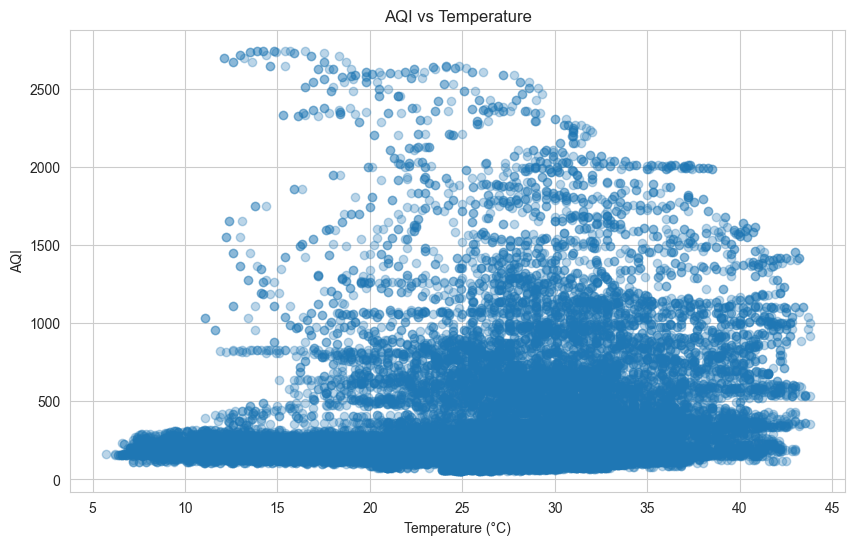

In [15]:
plt.figure(figsize=(10, 6))

plt.scatter(
    data["temp_c"],
    data["aqi_index"],
    alpha=0.3
)

plt.title("AQI vs Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("AQI")

plt.grid(True)
plt.show()


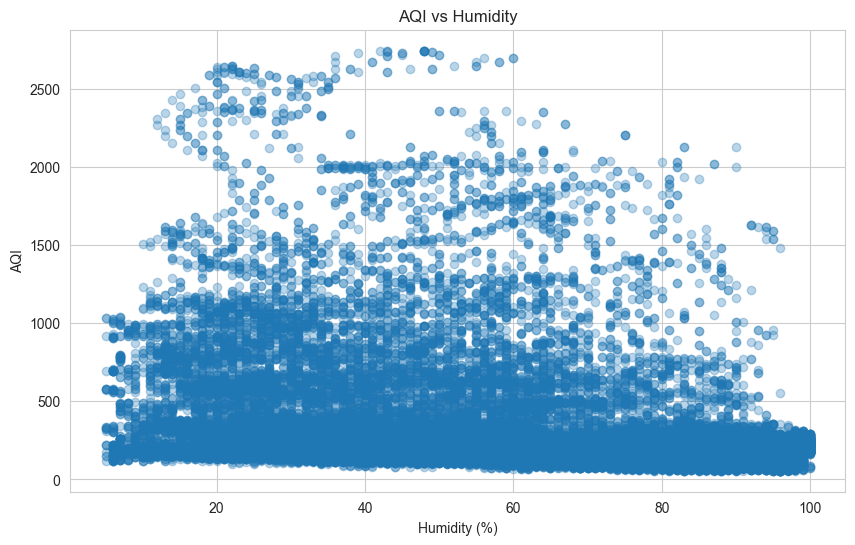

In [16]:
plt.figure(figsize=(10, 6))

plt.scatter(
    data["humidity"],
    data["aqi_index"],
    alpha=0.3
)

plt.title("AQI vs Humidity")
plt.xlabel("Humidity (%)")
plt.ylabel("AQI")

plt.grid(True)
plt.show()

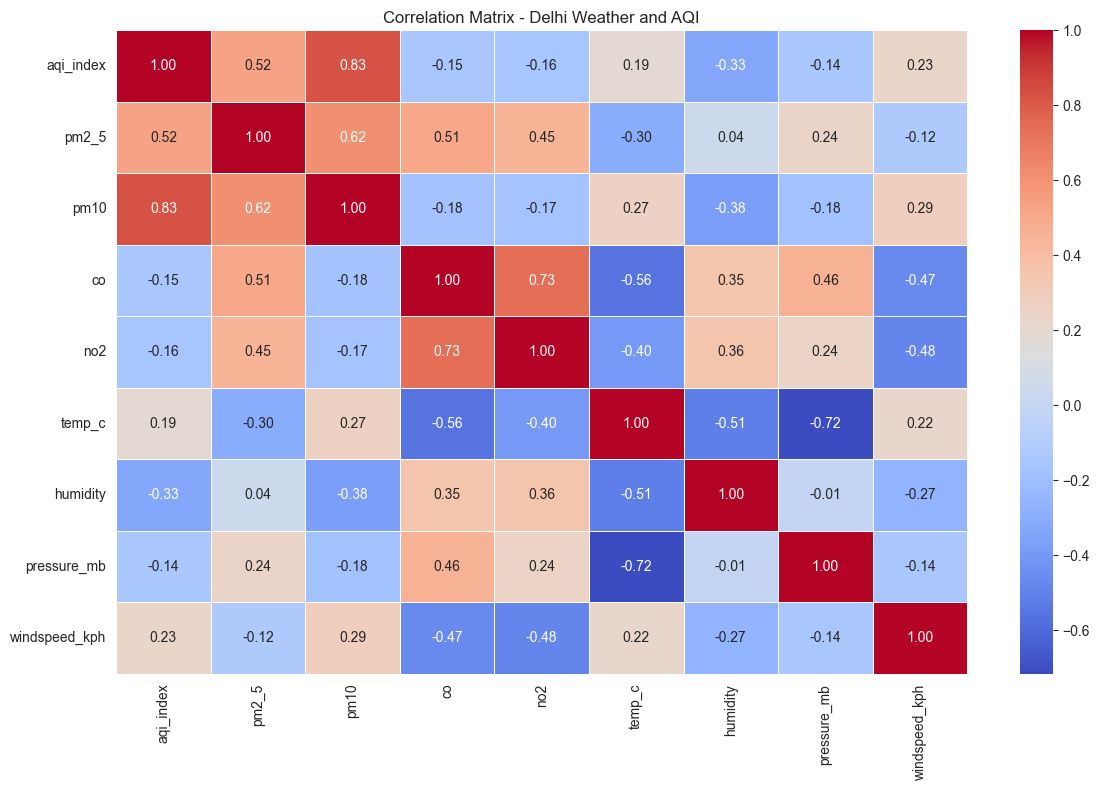

In [17]:
correlation_columns = [
    "aqi_index",
    "pm2_5",
    "pm10",
    "co",
    "no2",
    "temp_c",
    "humidity",
    "pressure_mb",
    "windspeed_kph"
]

correlation = data[correlation_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix - Delhi Weather and AQI")

plt.tight_layout()
plt.show()

In [18]:
print("========== DATASET SUMMARY ==========")

print("Total records:", len(data))
print("Total locations:", data["location"].nunique())

print(
    "Date range:",
    data["datetime"].min(),
    "to",
    data["datetime"].max()
)

print(
    "\nAverage AQI:",
    round(data["aqi_index"].mean(), 2)
)

print(
    "Maximum AQI:",
    data["aqi_index"].max()
)

print(
    "Minimum AQI:",
    data["aqi_index"].min()
)

print("\nAverage pollutant levels:")
print(
    data[["pm2_5", "pm10", "co", "no2"]].mean()
)

========== DATASET SUMMARY ==========
Total records: 52560
Total locations: 6
Date range: 2025-01-01 00:00:00 to 2025-12-31 23:00:00

Average AQI: 287.36
Maximum AQI: 2742
Minimum AQI: 56

Average pollutant levels:
pm2_5     89.542432
pm10     300.462700
co       863.844273
no2       35.442757
dtype: float64
